# 05. Decision Tree Regressor

**Project** · Used Car Price Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

A regression tree divides numeric outcomes into groups and estimates each group using one constant. For used cars, it can learn separate price rules for newer low-mileage cars and older high-mileage cars, with accident history affecting some branches.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Starting value increases with engine capacity and decays exponentially with vehicle age and mileage. Previous owners and accident severity reduce price. Gaussian noise with standard deviation 1,500 USD represents unobserved factors, and resale values are floored at 800 USD.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `vehicle_age_years` | integer | years | Age of the used vehicle |
| `kilometres_driven` | integer | km | Odometer reading |
| `engine_capacity_l` | decimal | litres | Engine displacement |
| `previous_owners` | integer | count | Number of previous owners |
| `accident_history` | string | None, Minor or Major | Severity of recorded accident history |
| `resale_price_usd` | decimal | USD | Observed continuous outcome |

**Independent variables (X)** · `vehicle_age_years`, `kilometres_driven`, `engine_capacity_l`, `previous_owners`, `accident_history`.

**Dependent variable (y)** · `resale_price_usd` is the continuous quantity to predict in USD. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "05_used_car_prices.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history,resale_price_usd
0,18,324142,1.6,2,None,1833.38
1,1,23186,3.0,1,Minor,29957.12
2,15,251293,1.0,2,None,1941.83
3,18,213261,3.0,3,None,5927.58
4,7,113443,3.0,2,None,15716.93
5,15,174299,2.0,3,None,5336.98
6,12,229750,2.0,4,None,4879.05
7,13,183916,1.6,3,None,4042.57
8,14,128350,3.0,4,None,7063.71
9,17,324183,3.0,6,Minor,800.00


vehicle_age_years      int64
kilometres_driven      int64
engine_capacity_l    float64
previous_owners        int64
accident_history         str
resale_price_usd     float64
dtype: object

## 3. Mathematical Understanding

With squared-error splitting, the node prediction is $\bar y=(1/n)\sum_i y_i$, where $y_i$ is one of the $n$ target values in that node. Node error is $S=\sum_i(y_i-\bar y)^2$. Evaluate a split by $S_P-S_L-S_R$, where $P$ is the parent and $L,R$ are the children. In each child use its own mean.

For observed prices of 8, 10, 18 and 20 thousand USD, the parent mean is 14 and $S_P=104$ in squared thousands of dollars. If a mileage cutoff separates $[8,10]$ from $[18,20]$, child means are 9 and 19 and child errors are 2 and 2. The gain is $104-2-2=100$. A new car routed to the first leaf receives 9,000 USD.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/tree.html)

## 4. Working Principle

Sort candidate feature values, test possible cutoffs and compare the error before and after splitting. Continue to refine groups while the stopping rules allow. A new example follows one path and takes the training mean from its leaf under squared error.

| Node | Prices in thousands of USD | Mean |
| --- | --- | --- |
| Parent | 8, 10, 18, 20 | 14 |
| Left leaf | 8, 10 | 9 |
| Right leaf | 18, 20 | 19 |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Partitions inputs and predicts a leaf mean or median` → `Estimate in USD`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "resale_price_usd"
FEATURES = ["vehicle_age_years","kilometres_driven","engine_capacity_l","previous_owners","accident_history"]
NUMERIC = ["vehicle_age_years","kilometres_driven","engine_capacity_l","previous_owners"]
CATEGORICAL = ["accident_history"]
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vehicle_age_years  1500 non-null   int64  
 1   kilometres_driven  1500 non-null   int64  
 2   engine_capacity_l  1470 non-null   float64
 3   previous_owners    1500 non-null   int64  
 4   accident_history   1470 non-null   str    
 5   resale_price_usd   1500 non-null   float64
dtypes: float64(2), int64(3), str(1)
memory usage: 76.7 KB


,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history,resale_price_usd
0,18,324142,1.6,2,None,1833.38
1,1,23186,3.0,1,Minor,29957.12
2,15,251293,1.0,2,None,1941.83
3,18,213261,3.0,3,None,5927.58
4,7,113443,3.0,2,None,15716.93


,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history,resale_price_usd
1495,16,273288,2.0,1,None,4340.79
1496,4,24682,2.0,1,None,22480.85
1497,8,57963,3.0,2,Minor,16204.87
1498,3,57058,1.0,1,None,17673.61
1499,10,103449,2.0,3,None,6837.48


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
vehicle_age_years,1500.0,NaN,NaN,NaN,9.459333,5.125283,1.0,5.0,9.0,14.0,18.0
kilometres_driven,1500.0,NaN,NaN,NaN,121992.815333,73024.504925,7711.0,65094.0,109944.5,167148.5,339579.0
engine_capacity_l,1470.0,NaN,NaN,NaN,1.9,0.697394,1.0,1.2,2.0,2.5,3.0
previous_owners,1500.0,NaN,NaN,NaN,2.353333,1.346241,1.0,1.0,2.0,3.0,6.0
accident_history,1470,3,None,1090,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resale_price_usd,1500.0,NaN,NaN,NaN,11357.02206,7193.344405,800.0,5650.925,9787.55,16011.1875,33042.69


,Missing,Missing %
vehicle_age_years,0,0.0
kilometres_driven,0,0.0
engine_capacity_l,30,2.0
previous_owners,0,0.0
accident_history,30,2.0
resale_price_usd,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

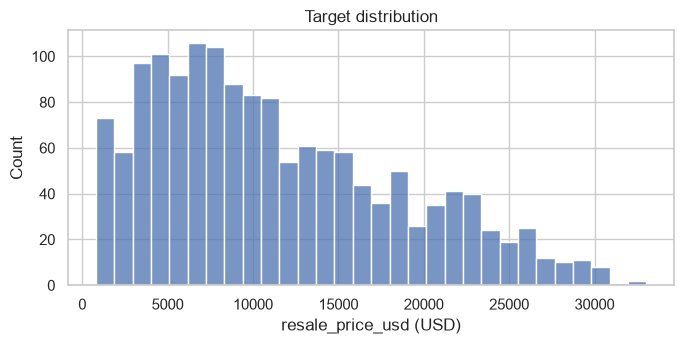

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("resale_price_usd (USD)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

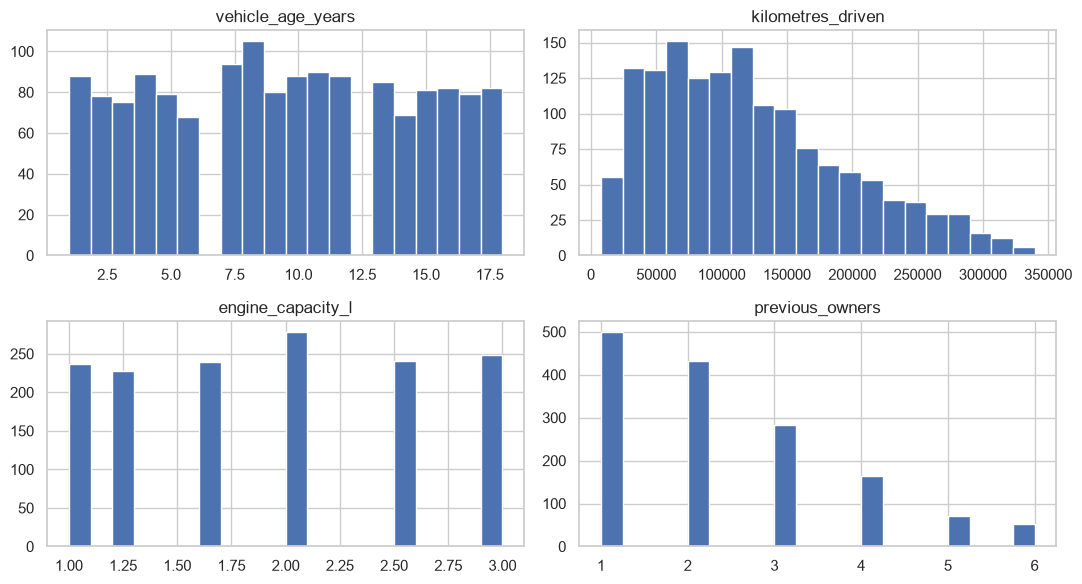

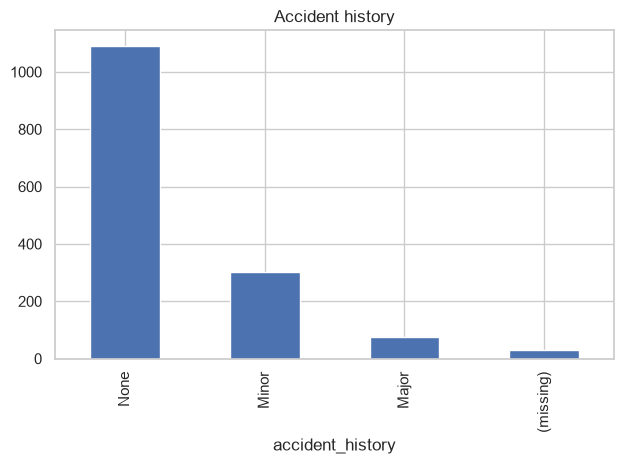

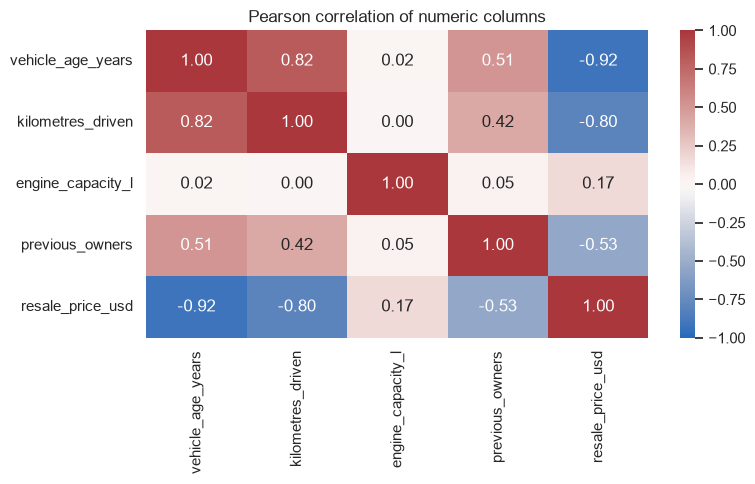

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

df["accident_history"].fillna("(missing)").value_counts().plot.bar()
plt.title("Accident history")
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. The categorical branch fills blanks with the most common training level and one-hot encodes levels. An unseen level becomes an all-zero block. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

# Fill blank categories, then make one indicator column per category.
category_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
        ("categorical", category_preprocess, CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`max_depth` and `min_samples_leaf` trade precision for stable estimates. `min_samples_split` controls when splitting is allowed. With `criterion='absolute_error'`, terminal predictions are medians, which are less sensitive to extreme prices. That candidate can be slower to train.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

estimator = DecisionTreeRegressor(max_depth=6, min_samples_leaf=15, random_state=SEED)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [ ]:
# Learn from the training rows.
model.fit(X_train, y_train)

### Predict on the test rows

In [ ]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} USD")

,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history
1116,16,158084,NaN,2,None


Example prediction: 3,698.47 USD


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · USD.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE        1552.664
MSE     3758152.912
RMSE       1938.596
R²            0.917
Name: Test score, dtype: float64

### Compare with a simple baseline

In [ ]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,5649.982,4.568447e+07,6759.029,-0.009
Model,1552.664,3.758153e+06,1938.596,0.917


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

The plot shows the early branches and their group mean estimates in USD. A terminal prediction uses the mean at the reached leaf. Ellipses indicate branches omitted from the rendering.

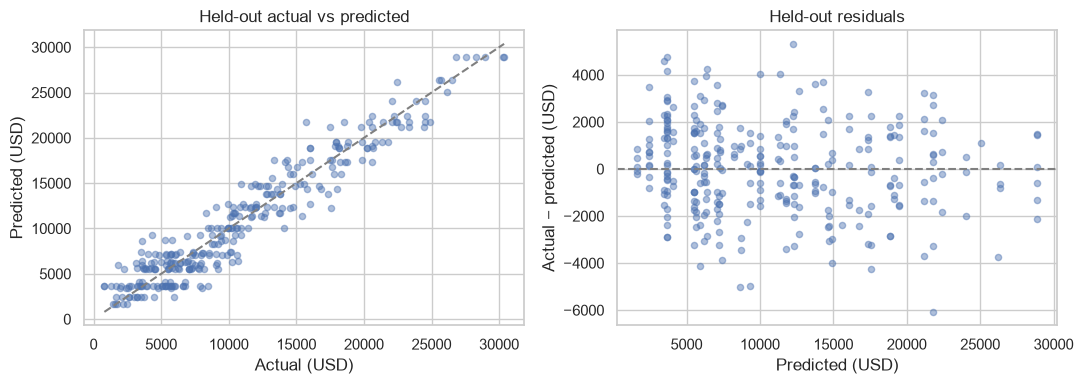

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (USD)", ylabel="Predicted (USD)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (USD)", ylabel="Actual − predicted (USD)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

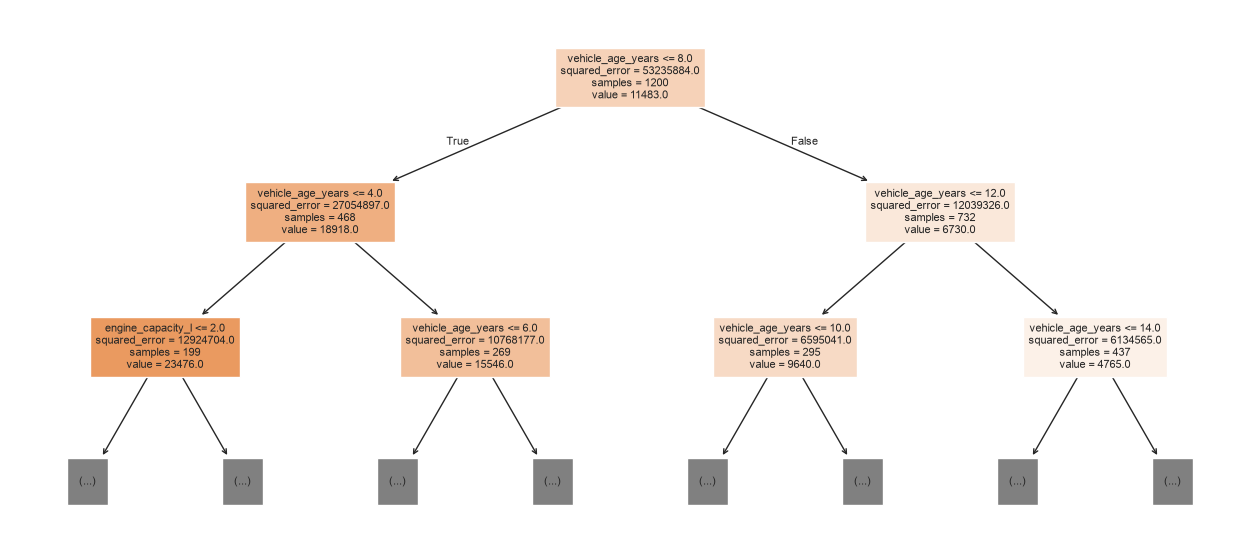

In [ ]:
tree = model.named_steps["model"]
feature_names = model.named_steps["preprocess"].get_feature_names_out()
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=feature_names, filled=True, max_depth=2, fontsize=8, precision=0)
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`max_depth` and `min_samples_leaf` trade precision for stable estimates. `min_samples_split` controls when splitting is allowed. With `criterion='absolute_error'`, terminal predictions are medians, which are less sensitive to extreme prices. That candidate can be slower to train.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {"model__max_depth": [3, 6, None], "model__min_samples_split": [20, 50], "model__criterion": ["squared_error", "absolute_error"]}
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [ ]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__criterion': 'squared_error', 'model__max_depth': None, 'model__min_samples_split': 20}


,rank_test_score,Mean fold RMSE,std_test_score,params
4,1,2130.095,82.077,"{'model__criterion': 'squared_error', 'model__..."
2,2,2142.530,62.980,"{'model__criterion': 'squared_error', 'model__..."
10,3,2179.992,144.464,"{'model__criterion': 'absolute_error', 'model_..."
8,4,2199.226,119.271,"{'model__criterion': 'absolute_error', 'model_..."
5,5,2211.560,26.230,"{'model__criterion': 'squared_error', 'model__..."


### Compare the models on the test set

In [ ]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,5649.982,4.568447e+07,6759.029,-0.009
First model,1552.664,3.758153e+06,1938.596,0.917
Tuned model,1546.937,3.642138e+06,1908.439,0.920


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in USD and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [ ]:
examples = pd.DataFrame([
    [3, 38000, 1.8, 1, 'None'],
    [8, 106000, 2, 2, 'Minor'],
    [15, 196000, 1.6, 4, 'Major'],
], columns=FEATURES)
display(examples)

,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history
0,3,38000,1.8,1,None
1,8,106000,2.0,2,Minor
2,15,196000,1.6,4,Major


### Make predictions

In [ ]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Newer, low-mileage car","Mid-age car with a minor accident","Older, high-mileage car with a major accident"]
example_output["Predicted resale_price_usd (USD)"] = sample_predictions.round(2)
display(example_output)

,vehicle_age_years,kilometres_driven,engine_capacity_l,previous_owners,accident_history,Scenario,Predicted resale_price_usd (USD)
0,3,38000,1.8,1,None,"Newer, low-mileage car",21299.67
1,8,106000,2.0,2,Minor,Mid-age car with a minor accident,8622.37
2,15,196000,1.6,4,Major,"Older, high-mileage car with a major accident",3168.16


## 12. Limitations and Advantages

A tree works on nonlinear, mixed-feature problems after encoding and gives interpretable paths. The squared-error version is sensitive to outliers and produces jumps at split thresholds. A shallow tree may merge distinct price groups, while a deep tree can chase noise. Leaf estimates generally stay within observed target values. Use a tree to examine price segments. Use a smoother or structurally constrained approach when gradual change or extrapolation matters.

## 13. Interview Preparation

### A. 30-second explanation

> I used a regression tree to split synthetic cars into price segments. The default criterion chooses cutoffs that reduce squared errors, and each leaf predicts the mean resale price of its training cars. I assessed dollar errors on a holdout and compared depth and split criteria using training folds.

### B. 90-second technical explanation

> I used a regression tree to split synthetic cars into price segments. The default criterion chooses cutoffs that reduce squared errors, and each leaf predicts the mean resale price of its training cars. I assessed dollar errors on a holdout and compared depth and split criteria using training folds. My target was resale price usd, and the inputs were vehicle age years, kilometres driven, engine capacity l, previous owners, accident history. Sort candidate feature values, test possible cutoffs and compare the error before and after splitting. Continue to refine groups while the stopping rules allow. A new example follows one path and takes the training mean from its leaf under squared error. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in USD and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **How does a regression leaf predict?** It predicts a mean for squared error and a median for absolute error.
2. **How does it differ from a classifier?** It splits to reduce numeric prediction error and predicts a continuous value.
3. **What is the effect of max_depth?** It caps how many sequential conditions can define a leaf.
4. **Why can the prediction be discontinuous?** Crossing a threshold sends a row to a different constant-valued leaf.
5. **Can the tree extrapolate trends?** It routes extreme inputs to existing leaves and keeps their learned constants.
6. **What does the absolute-error criterion change?** It compares absolute deviations around node medians.
7. **Why inspect leaf sample count?** A small leaf estimate can have high variance.
8. **What is the root prediction?** The fitted value from all training targets before any split.
9. **Do categories become ordered automatically?** One-hot encoding treats their levels as separate indicators in this pipeline.
10. **Why report both MAE and RMSE?** RMSE more strongly reflects large misses than MAE.

### D. Five scenario questions

1. **A luxury car produces a very large residual. What would you inspect?** Check its representation in training, compare MAE and RMSE, and examine premium-car residuals.
2. **Two almost identical cars get very different estimates. Why?** They cross a split, so the tree predicts distinct leaf means.
3. **How would you stabilize a volatile leaf?** Increase its minimum size or compare with an ensemble.
4. **You must predict rare accident categories. What should you check?** Count training rows with that category and validate subgroup error.
5. **A smooth depreciation formula is available. How could you use it?** Compare its held-out errors and stability with the tree.

### E. Three common mistakes

- Using classification impurity for prices. Use a numeric-loss criterion.
- Comparing MSE directly to USD. Use RMSE or MAE for dollar errors.
- Assuming greater depth always helps. Compare held-out training-fold scores.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [ ]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for used car price prediction using Decision Tree Regressor. I generated 1,500 synthetic observations and used vehicle age years, kilometres driven, engine capacity l, previous owners, accident history to predict resale price usd. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} USD, "
    f"compared with {baseline_metrics['MAE']:,.2f} USD for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} USD. "
    "I plotted the shallow part of the tree to explain how groups of cars received different leaf-level estimates. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for used car price prediction using Decision Tree Regressor. I generated 1,500 synthetic observations and used vehicle age years, kilometres driven, engine capacity l, previous owners, accident history to predict resale price usd. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 1,546.94 USD, compared with 5,649.98 USD for the training-mean baseline. Its RMSE was 1,908.44 USD. I plotted the shallow part of the tree to explain how groups of cars received different leaf-level estimates. These results apply to the synthetic data and should be validated on representative observations before practical use.